# 20261029 - Linear Algebra

- As we've seen, executing even basic mathematical operations at max performance on hardware is *hard*
	- Many different moving parts
        - Cache sizes, vector instruction widths, memory access patterns, instruction level-parallelism
	- Plenty of "gotchas"
        - Cache coherency, cache thrashing, uncooperative compilers
- Luckily, there is a lot of overlap between the work that scientific codes do.
- Today, we'll talk about the most fundamental building blocks that you can do: Linear Algebra
	- and specifically how you should nearly always use a library to handle them.

## BLAS (Basic Linear Algebra Subprograms)
- Originally released in the late 70s as a Fortran library
- Available through the legendary [netlib website](https://netlib.org/)
- BLAS is what powers many of the most popular "array" libraries out there
    - Julia has BLAS built right into the language
    - Numpy makes [heavy usage of BLAS](https://numpy.org/doc/stable/building/blas_lapack.html) in the backend

In [2]:
import numpy as np
np.__config__.show()
np.__version__

Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.14.3/lib/python3.14/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.14.3/lib/python3.14/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.33.112.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.33.112.0
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.14.3/lib/python3.14/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.14.3/lib/python3.14/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.33.112.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.33.112.0
Compilers:
  c:
    commands: cc
 

'2.5.1'

- Basic functionality on [3 levels](https://netlib.org/blas/index.html#_reference_blas_now_part_of_lapack_release)
    - Level 1: Vector Operations
        - Dot product, scaled vector addition
    - Level 2: Generalized Matrx-Vector (gemv)
    - Level 3: Generalized Matrix-Matrix (gemm)

- The naming of the operations in this library have (in some cases) become universal
    - Notably, `AXPY` to denote $\mathbf{y} = \alpha \mathbf{x} + \mathbf{y}, \quad \alpha \in \mathbb{F} \text{ and } \mathbf{x}, \mathbf{y} \in \mathbb{F}^n$

- Many Implementations
    - Many add multi-threaded functionality
    - Some have extra functions beyond the BLAS standard
    - May have different numerical precision options available
   

- Examples:
    - [BLIS](https://github.com/flame/blis)
        - Portable, high performance library built on micro-kernels (we'll talk about that in a bit)
    - [Intel MKL](https://www.intel.com/content/www/us/en/developer/tools/oneapi/onemkl.html) (Math Kernel Library)
        - Intel-specialized BLAS-like library
    - [cuBLAS](https://developer.nvidia.com/cublas)
        - BLAS, but for NVIDIA GPUs and CUDA
    - [libXSMM](https://libxsmm.readthedocs.io/en/latest/)
        - Specializes in matrix-matrix multiplication
        - Uses compiler-independent Just-in-Time compilation to create custom kernels depending on the matrix size

### BLIS microkernels

![BLIS cache](../img/blis-cache.png)

![BLIS gemm kernel](../img/blis-gemm-kernels.png)

## LAPACK (Linear Algebra Package)
- Above the normal matrix operations are
- But there are other common matrix algebra operations that are quite common as well
    - Solving linear system of equations, $\mathbf{Ax} = \mathbf{y}$
    - Eigenvalue or singular value decompositions
    - Matrix factorizations (LU, QR, Choelsky)
These are often grouped together in LAPACK

- Similar origin story as BLAS
    - Descended in University of Tennessee
    - Hosted on netlib
    - Originally in Fortran
    - Many libraries implementing similar functionality often use the same function [naming scheme](https://en.wikipedia.org/wiki/LAPACK#Naming_scheme)

- In a similar vein, many other implementations (or sub implementations) have been released
    - [LAPACK](https://netlib.org/lapack/)
        - The original Fortran, still available
    - [MAGMA](https://icl.utk.edu/magma/) (Matrix Algebra on GPU and Multicore Architectures)
    	- heterogenous (CPU and GPU together) BLAS/LAPACK
    - [Kokkos-Kernels](https://kokkos.org/kokkos-kernels/docs/)
        - Portable LAPACK/BLAS kernels written in Kokkos (GPU-capable programming model)
    - [Eigen](https://libeigen.gitlab.io/)
        - Standard C++ matrix-algebra library (equivalent to `numpy` for Python, but not as universal)
    - Many of the above mentioned "BLAS" libraries also implement some LAPACK functionality

## Dense vs Sparse Matrix
- Vectors (nearly) always treated as dense
    - Perhaps banded, but underlying data structure is contiguous
- Many/most scientific matrices are sparse
    - Contain many, many more zeros than they do
    - Exact definition of "sparse" is ambiguous, but at least 99% zero elements
- Dense matrices exist in scientific computing, but are usually much smaller than the problem size

### Aside: Nomenclature
- There are two different concepts when we talk about dense and sparse matrices
1. The character of the matrix entries (e.g. how many non-zero values are there)
2. The format a matrix is stored in a computer

It is possible to store a sparse matrix (in character) using a dense matrix format.

### Dense Matrix Storage
- Easiest way to store a matrix is as a dense, contiguous array of memory
- C standard is row-major ordering (list of lists), while Fortran standard is column-major ordering
    - Performance implications for either choice, one is not worse than the other
    - Row-major ordering is more popular

![wiki row-major](https://thumb.wikimedia.org/wikipedia/commons/thumb/4/4d/Row_and_column_major_order.svg/960px-Row_and_column_major_order.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail)

Algorithm for densely stored matrix:

```c
aptr = 0;
for (row=0; row<nrows; row++) {
  s = 0;
  for (col=0; col<ncols; col++) {
    s += a[aptr] * x[col];
    aptr++;
  }
  y[row] = s;
}
```

- If `a` is mostly zeros, then we do a lot of work for nothing
- Additionally, `a` is wasting space in general

### Sparse Matrix Storage
- We have two primary concerns
    - Space savings
    - Computational efficiency
- If we only cared about space savings, this becomes a pure data-compression problem
- We really want to handle both

General idea:
![image](../img/sparse_matrix_diagram_ArtOfHPC.png)

In [13]:
%matplotlib inline
import scipy as sp
import scipy.sparse as sparse
import scipy.sparse.linalg as sla

### Coordinate format (COO)
- By far the simplest, not always the best
- Store the following triple for each non-zero entry: `value, row, column`
    - `value` is the actual matrix entry value
    - `row` and `column` denote the location (coordinate) where the value should go

In [14]:
row  = [0,2,1]
col  = [0,2,1]
val  = [1,1,1]

S = sparse.coo_matrix((val, (row,col)), shape=(3,3))
S.toarray()

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

Easy to add on new values

In [15]:
row  = [0,1,2,2]
col  = [0,1,2,0]
val  = [1,1,1,2]

S = sparse.coo_matrix((val, (row,col)), shape=(3,3))
S.toarray()

array([[1, 0, 0],
       [0, 1, 0],
       [2, 0, 1]])

Visualize the sparsity pattern using `spy`:

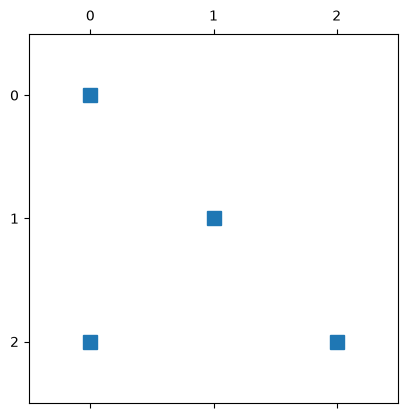

In [10]:
plt.spy(S)
plt.show()

Pros and cons of coordinate sparse format
- Pro:
    - Coordinate format is incredibly flexible, doesn't require any knowledge of the sparsity pattern of the matrix
- Con:
    - Poor computational efficiency (data can be located anywhere, no hope or guarantee of cache locality or vectorization)
    - Poor storage efficiency (if I have many values in a compact space, I still need 3 values for each of them)

### Compressed Sparse Row (CSR)

- Store contiguous rows of the data, and provide coordinate for where they need to go 
    - Can also do contiguous columns of data, called CSC

![CSR](../img/Illustration-of-the-CSR-storage-format.png)

*From [here](https://www.researchgate.net/figure/Illustration-of-the-CSR-storage-format_fig4_381005380)*

- Contiguous rows allows for best cache locality in matrix-vector product
    - CSC best for matrix-transpose-vector product

In [17]:
ptr = [0,2,4,5]
col = [0,2,0,1,2]
val = [1,2,3,1,1]

S = sparse.csc_matrix((val, row, ptr), shape=(3,3))
S.toarray()

ValueError: indices and data should have the same size

Matrix-Vector product using a sparse matrix representation

```c
aptr = 0;
for (row=0; row<nrows; row++) {
  s = 0;
  for (icol=ptr[row]; icol<ptr[row+1]; icol++) {
    int col = ind[icol];
    s += a[aptr] * x[col];
    aptr++;
  }
  y[row] = s;
}
```

- We have non-uniform memory access
    - Potentially poor cache locality
    - Really difficult/impossible to vectorize